# 01b Exploratory data analysis
A first look at delays, their causes, patterns over time, suspicious values and how many flights each route + airline pair has. Each section supports a project decision: medians for extreme delays, the split by month, and the minimum number of flights per pair. Nothing is cleaned or dropped here.

**Before running:** select the "Python (ctds)" kernel and run the notebook from the `notebooks/` folder (see the README). Set `USE_SAMPLE = True` only for quick tests; reported results use the full data.

In [1]:
# imports
import sys
sys.path.append("..")  # lets us import the src/ folder from the project root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import FLIGHTS_PARQUET, SAMPLE_PARQUET, TABLES_DIR, FIGURES_DIR
from src.data_loading import load_flights

In [2]:
# settings
USE_SAMPLE = False  # True only for quick tests; it overwrites the saved tables and figures
PATH = SAMPLE_PARQUET if USE_SAMPLE else FLIGHTS_PARQUET

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:,.3f}".format)


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"01b_{name}.png", dpi=150)
    plt.show()

In [3]:
# load only the columns this notebook needs
CAUSES = ["carrier_delay", "weather_delay", "nas_delay", "security_delay", "late_aircraft_delay"]
columns = ["fl_date", "month", "day_of_week", "op_unique_carrier", "origin", "dest",
           "crs_dep_time", "crs_elapsed_time", "distance", "cancelled", "diverted",
           "dep_delay", "arr_delay"] + CAUSES
df = load_flights(PATH, columns=columns)


# only completed flights have an arrival delay
completed = (df["cancelled"] == 0) & (df["diverted"] == 0)
df_done = df[completed]

print(f"Data: {PATH.name} | flights: {len(df):,} | completed: {len(df_done):,}")

Data: flights_2024.parquet | flights: 7,079,081 | completed: 6,965,267


## 1. Arrival delay distribution
Only completed flights have an arrival delay, so cancelled and diverted flights are left out. The right tail is long, so we compare groups with medians rather than means.

In [4]:
# percentiles of the arrival delay
arr = df_done["arr_delay"].dropna()
print(f"Completed flights with arr_delay: {len(arr):,}")

q = arr.quantile([0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999, 1]).rename("arr_delay_min")
q.index = [f"{p:.1%}" for p in q.index]
display(q.to_frame())
q.to_frame().to_csv(TABLES_DIR / "01b_arr_delay_quantiles.csv")

Completed flights with arr_delay: 6,965,267


,arr_delay_min
0.0%,-126.000
1.0%,-37.000
5.0%,-27.000
25.0%,-15.000
50.0%,-6.000
75.0%,9.000
95.0%,83.000
99.0%,215.000
99.9%,753.000
100.0%,"3,803.000"


In [5]:
# how many flights are in the tail, for fixed limits and for the top percentiles
p99 = arr.quantile(0.99)
p999 = arr.quantile(0.999)
thresholds = {
    "> 180 min": 180,
    "> 360 min": 360,
    f"> p99 ({p99:.0f} min)": p99,
    f"> p99.9 ({p999:.0f} min)": p999,
}

counts = []
for limit in thresholds.values():
    counts.append((arr > limit).sum())

tail = pd.DataFrame({"flights": counts}, index=thresholds.keys())
tail["share"] = tail["flights"] / len(arr)
display(tail)
tail.to_csv(TABLES_DIR / "01b_arr_delay_tail.csv")

print(f"Share 15+ min late: {(arr >= 15).mean():.1%}")

,flights,share
> 180 min,99468,0.014
> 360 min,23529,0.003
> p99 (215 min),69002,0.010
> p99.9 (753 min),6957,0.001


Share 15+ min late: 20.8%


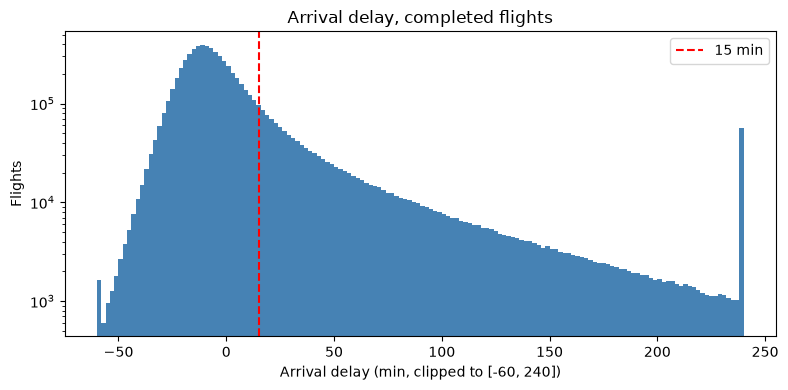

In [6]:
# histogram; clipped to [-60, 240] and on a log scale so the tail stays visible
# the end bars also hold every flight beyond the clip range
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(arr.clip(-60, 240), bins=150, color="steelblue")
ax.axvline(15, color="red", ls="--", label="15 min")
ax.set(xlabel="Arrival delay (min, clipped to [-60, 240])", ylabel="Flights", title="Arrival delay, completed flights")
ax.set_yscale("log")
ax.legend()
save_fig(fig, "arr_delay_hist")

## 2. Delay causes
For flights 15+ minutes late, we split all delay minutes by cause. This shows why flights are late, and RQ1 later compares these shares between clusters. Two late flights have every cause at 0 and are left out.

In [7]:
# late flights; the two with every cause at 0 carry no cause information
late = df_done[df_done["arr_delay"] >= 15]
all_zero = late[CAUSES].fillna(0).sum(axis=1) == 0
print(f"Late flights: {len(late):,} | excluded (all causes 0): {all_zero.sum()}")
late = late[~all_zero]


# share of delay minutes per cause, and how often each cause appears
minutes = late[CAUSES].sum()
share_of_minutes = minutes / minutes.sum()
share_of_flights = (late[CAUSES] > 0).mean()

cause_tab = pd.DataFrame({
    "minutes": minutes,
    "share_of_minutes": share_of_minutes,
    "share_of_flights_with_cause": share_of_flights,
})
display(cause_tab)
cause_tab.to_csv(TABLES_DIR / "01b_delay_causes.csv")

Late flights: 1,449,972 | excluded (all causes 0): 2


,minutes,share_of_minutes,share_of_flights_with_cause
carrier_delay,"35,823,264.000",0.345,0.544
weather_delay,"6,195,873.000",0.060,0.061
nas_delay,"19,621,994.000",0.189,0.501
security_delay,"179,928.000",0.002,0.005
late_aircraft_delay,"41,974,008.000",0.404,0.513


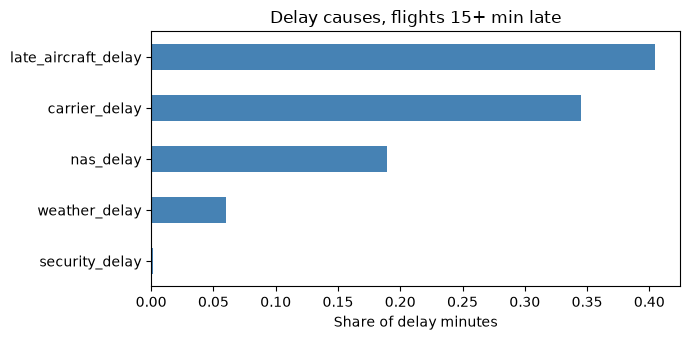

In [8]:
# bar chart, sorted so the largest cause is at the top
fig, ax = plt.subplots(figsize=(7, 3.5))
cause_tab["share_of_minutes"].sort_values().plot.barh(ax=ax, color="steelblue")
ax.set(xlabel="Share of delay minutes", title="Delay causes, flights 15+ min late")
save_fig(fig, "delay_causes")

## 3. Patterns over time
Per month, weekday and scheduled departure hour, we compute the share of completed flights 15+ minutes late and the share of all flights cancelled. Delays change a lot during the year, so a random split would mix seasons; RQ3 therefore trains on earlier months and tests on later ones. The hour is `crs_dep_time // 100`, with 24 mapped to 0.

In [9]:
# hour of departure; % 24 turns the hour 24 (midnight written as 2400) into 0
df["hour"] = (df["crs_dep_time"] // 100).astype(int) % 24

# late15 is empty for cancelled and diverted flights, so its mean only uses completed flights
df["late15"] = np.where(completed, df["arr_delay"] >= 15, np.nan)


def rates(key):
    grouped = df.groupby(key)
    return grouped.agg(flights=("cancelled", "size"), late15_share=("late15", "mean"),
                       cancel_rate=("cancelled", "mean"))


tables = {}
for key in ["month", "day_of_week", "hour"]:
    tables[key] = rates(key)
    print(key)
    display(tables[key])
    tables[key].to_csv(TABLES_DIR / f"01b_rates_by_{key}.csv")

month


,flights,late15_share,cancel_rate
month,,,
1,547271,0.241,0.037
2,519221,0.159,0.006
3,591767,0.208,0.009
4,582205,0.191,0.007
5,609743,0.264,0.014
6,611132,0.249,0.013
7,634613,0.296,0.029
8,619025,0.235,0.021
9,582622,0.155,0.006


day_of_week


,flights,late15_share,cancel_rate
day_of_week,,,
1,1073959,0.206,0.014
2,976073,0.179,0.013
3,973179,0.187,0.012
4,1041956,0.219,0.014
5,1055419,0.233,0.015
6,911515,0.204,0.012
7,1046980,0.225,0.014


hour


,flights,late15_share,cancel_rate
hour,,,
0,12332,0.200,0.016
1,4077,0.213,0.017
2,1543,0.208,0.019
3,1093,0.195,0.022
4,534,0.202,0.015
5,200157,0.091,0.013
6,495017,0.096,0.013
7,493915,0.123,0.012
8,482402,0.139,0.011


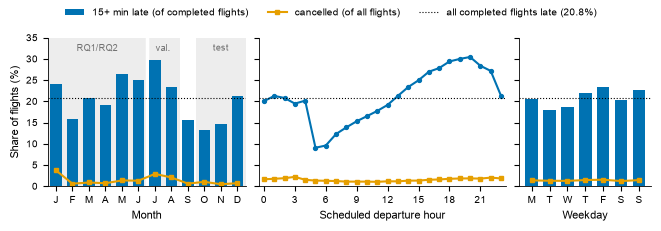

In [10]:
# figure 1 of the report: late share and cancellation rate by month, scheduled hour and weekday
paper_style = {"font.size": 8, "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
               "axes.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
               "xtick.labelsize": 7, "ytick.labelsize": 7, "lines.linewidth": 1.5,
               "legend.fontsize": 7, "legend.frameon": False}
LATE = "#0072B2"    # Okabe-Ito blue and orange, readable for colour-blind readers
CANCEL = "#E69F00"
overall = (df_done["arr_delay"] >= 15).mean() * 100

with plt.rc_context(paper_style):
    fig, axes = plt.subplots(1, 3, figsize=(16.5 / 2.54, 5.6 / 2.54), layout="constrained",
                             gridspec_kw={"width_ratios": [1.2, 1.5, 0.8]}, sharey=True)

    # month, with the periods used later in the project as light grey bands
    ax = axes[0]
    for lo, hi, label in [(0.5, 6.5, "RQ1/RQ2"), (6.5, 8.5, "val."), (9.5, 12.5, "test")]:
        ax.axvspan(lo, hi, color="0.93", zorder=0, linewidth=0)
        ax.text((lo + hi) / 2, 33.5, label, ha="center", va="top", fontsize=6.5, color="0.45")
    ax.axvline(6.5, color="white", linewidth=2.5, zorder=0.5)
    t = tables["month"]
    ax.bar(t.index, t["late15_share"] * 100, width=0.7, color=LATE, label="15+ min late (of completed flights)")
    ax.plot(t.index, t["cancel_rate"] * 100, color=CANCEL, marker="s", markersize=2.8,
            label="cancelled (of all flights)")
    ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
    ax.set_xlim(0.5, 12.5)
    ax.set(xlabel="Month", ylabel="Share of flights (%)")

    # scheduled departure hour
    ax = axes[1]
    t = tables["hour"]
    ax.plot(t.index, t["late15_share"] * 100, color=LATE, marker="o", markersize=2.8)
    ax.plot(t.index, t["cancel_rate"] * 100, color=CANCEL, marker="s", markersize=2.8)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlim(-0.5, 23.5)
    ax.set_xlabel("Scheduled departure hour")

    # weekday
    ax = axes[2]
    t = tables["day_of_week"]
    ax.bar(t.index, t["late15_share"] * 100, width=0.7, color=LATE)
    ax.plot(t.index, t["cancel_rate"] * 100, color=CANCEL, marker="s", markersize=2.8)
    ax.set_xticks(range(1, 8), ["M", "T", "W", "T", "F", "S", "S"])
    ax.set_xlabel("Weekday")

    # one shared axis, so the two rates are compared on the same scale; the dotted line is the overall late share
    for ax in axes:
        ax.axhline(overall, color="black", linestyle=":", linewidth=0.8)
        ax.set_ylim(0, 35)

    # one legend for the whole figure
    # matplotlib lists lines before bars, so we reverse to put the delays first
    handles, labels = axes[0].get_legend_handles_labels()
    handles, labels = handles[::-1], labels[::-1]
    handles.append(plt.Line2D([], [], color="black", linestyle=":", linewidth=0.8))
    labels.append(f"all completed flights late ({overall:.1f}%)")
    fig.legend(handles, labels, loc="outside upper center", ncols=3)

    fig.savefig(FIGURES_DIR / "01b_rates_over_time.png", dpi=300)
    plt.show()

## 4. Suspicious values
We only report these here; the cleaning step in 01c removes the impossible ones. The implied speed is distance divided by scheduled duration. Because `crs_elapsed_time` includes taxi time, short flights look slow for normal reasons. We also list the earliest arrivals and count cancelled flights that still have a `dep_delay`.

In [11]:
# "> 0" is False for missing values, so this catches both missing and non-positive durations
bad_dur = ~(df["crs_elapsed_time"] > 0)
print(f"Flights with missing or non-positive scheduled duration: {bad_dur.sum():,}")


# implied speed in mph
sp = df[~bad_dur].copy()
sp["speed_mph"] = sp["distance"] / (sp["crs_elapsed_time"] / 60)
print(sp["speed_mph"].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).to_string())

Flights with missing or non-positive scheduled duration: 2


count   7,079,079.000
mean          308.632
std            84.436
min             4.796
0.1%           68.333
1%            103.500
50%           318.425
99%           470.526
99.9%         500.587
max         1,797.143


In [12]:
# the extremes at both ends
show = ["fl_date", "op_unique_carrier", "origin", "dest", "distance", "crs_elapsed_time", "speed_mph"]

print("10 slowest")
display(sp.nsmallest(10, "speed_mph")[show])

print("10 fastest")
display(sp.nlargest(10, "speed_mph")[show])

10 slowest


,fl_date,op_unique_carrier,origin,dest,distance,crs_elapsed_time,speed_mph
3920469,2024-07-23,NK,CLE,PIT,106.000,"1,326.000",4.796
3630921,2024-07-09,OO,JFK,LGA,11.000,60.000,11.000
2644350,2024-05-21,OO,ORD,FWA,157.000,491.000,19.185
2781856,2024-05-28,OO,ORD,SBN,84.000,260.000,19.385
5925937,2024-11-01,OO,FLG,PHX,119.000,362.000,19.724
6975303,2024-12-26,UA,LAX,SNA,36.000,107.000,20.187
957180,2024-02-23,YX,LGA,RIC,292.000,859.000,20.396
260458,2024-01-15,OO,PIB,MEI,69.000,171.000,24.211
488718,2024-01-28,OO,FOD,MCW,61.000,145.000,25.241
155283,2024-01-09,OO,MCW,FOD,61.000,140.000,26.143


10 fastest


,fl_date,op_unique_carrier,origin,dest,distance,crs_elapsed_time,speed_mph
5863595,2024-10-29,B6,MIA,BOS,"1,258.000",42.000,"1,797.143"
1020897,2024-02-27,NK,IND,ORD,177.000,6.000,"1,770.000"
1611678,2024-03-29,OO,ASE,AUS,812.000,45.000,"1,082.667"
3318114,2024-06-23,YX,ORF,LGA,296.000,24.000,740.000
147442,2024-01-09,AA,JAX,PHX,"1,786.000",161.000,665.590
5405007,2024-10-06,OH,DFW,GSO,999.000,95.000,630.947
1221797,2024-03-09,DL,DTW,TPA,983.000,95.000,620.842
1300054,2024-03-13,NK,LAS,EWR,"2,227.000",222.000,601.892
1435381,2024-03-20,NK,LAS,EWR,"2,227.000",222.000,601.892
1570717,2024-03-27,NK,LAS,EWR,"2,227.000",222.000,601.892


In [13]:
# flights that arrived far ahead of schedule
print("10 earliest arrivals")
display(df_done.nsmallest(10, "arr_delay")[["fl_date", "op_unique_carrier", "origin", "dest", "dep_delay", "arr_delay"]])


# some cancelled flights still have a departure delay
canc = df[df["cancelled"] == 1]
n_with_dep_delay = canc["dep_delay"].notna().sum()
share_with_dep_delay = canc["dep_delay"].notna().mean()
print(f"Cancelled flights: {len(canc):,} | with a dep_delay: {n_with_dep_delay:,} "
      f"({share_with_dep_delay:.1%})")

10 earliest arrivals


,fl_date,op_unique_carrier,origin,dest,dep_delay,arr_delay
6613729,2024-12-07,NK,BDL,FLL,-4.000,-126.000
766133,2024-02-13,NK,CMH,ORD,-96.000,-117.000
1144137,2024-03-05,B6,FLL,BOS,-10.000,-95.000
572175,2024-02-02,DL,JFK,SEA,-4.000,-91.000
5625842,2024-10-17,G4,BGR,PGD,-16.000,-91.000
517722,2024-01-30,B6,EWR,LAX,-12.000,-90.000
1394217,2024-03-18,DL,JFK,HNL,-10.000,-90.000
1122274,2024-03-04,AA,JFK,PHX,0.000,-89.000
570140,2024-02-02,B6,JFK,SFO,-14.000,-88.000
1198558,2024-03-08,AA,PHX,OGG,-12.000,-88.000


Cancelled flights: 96,315 | with a dep_delay: 3,345 (3.5%)


## 5. Minimum flights per route + airline pair
RQ1 builds one profile per route + airline pair, and pairs with very few flights give noisy profiles. For each threshold we count the pairs and flights that remain, for the full year and for months 1–6, the months RQ1 uses. In six months, weekly service means about 26 flights; we use 30.

In [14]:
# flights per pair, for the full year and for months 1-6
keys = ["op_unique_carrier", "origin", "dest"]
full = df.groupby(keys, observed=True).size()
h1 = df[df["month"] <= 6].groupby(keys, observed=True).size()


# pairs and flights kept for each threshold
rows = []
for t in [1, 12, 26, 30, 52, 100, 365]:
    for label, counts in [("full year (12 months)", full), ("months 1-6", h1)]:
        kept = counts >= t
        rows.append({"period": label, "min_flights": t, "pairs_kept": int(kept.sum()),
                     "pairs_share": kept.mean(), "flights_share": counts[kept].sum() / counts.sum()})


# one block of columns per period, so the two periods sit side by side
pairs = pd.DataFrame(rows).pivot(index="min_flights", columns="period")
pairs = pairs.reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0)

print(f"Pairs: full year {len(full):,}, months 1-6 {len(h1):,}")
print("Weekly ≈ 52 for the full year, ≈ 26 for months 1-6")
display(pairs)
pairs.to_csv(TABLES_DIR / "01b_min_flights_per_pair.csv")

Pairs: full year 13,258, months 1-6 12,184
Weekly ≈ 52 for the full year, ≈ 26 for months 1-6


period      full year (12 months)                           months 1-6  \
                    flights_share pairs_kept pairs_share flights_share   
min_flights                                                              
1                           1.000      13258       1.000         1.000   
12                          0.999      12003       0.905         0.998   
26                          0.998      11372       0.858         0.995   
30                          0.997      11233       0.847         0.993   
52                          0.994      10624       0.801         0.983   
100                         0.982       9514       0.718         0.953   
365                         0.873       5932       0.447         0.665   

period                              
            pairs_kept pairs_share  
min_flights                         
1                12184       1.000  
12               10964       0.900  
26               10266       0.843  
30               10007       0.821  
52                9143       0.750  
100               7679       0.630  
365               3083       0.253

## 5b. Late share per airline
RQ1 clusters route + airline pairs using only schedule and route features. If airlines differ a lot in delay rate, adding the airline to the clustering would mostly split the pairs by airline, so we leave it out of RQ1 and use it as a feature in the RQ3 model instead.

In [15]:
# late share per airline, from lowest to highest
late15 = df_done["arr_delay"] >= 15
by_airline = late15.groupby(df_done["op_unique_carrier"], observed=True)

airline = pd.DataFrame({"flights": by_airline.size(), "late15_share": by_airline.mean()})
airline = airline.sort_values("late15_share")

display(airline)
airline.to_csv(TABLES_DIR / "01b_late_by_airline.csv")

,flights,late15_share
op_unique_carrier,,
YX,295306,0.141
HA,77633,0.155
9E,195072,0.158
DL,997846,0.173
OO,733886,0.190
UA,745818,0.199
WN,1404597,0.206
MQ,275317,0.209
G4,114882,0.217


## 6. Takeaways
- Arrival delay (6,965,267 completed flights): the median is −6 minutes, the 99th percentile 215 minutes, the 99.9th 753 minutes and the maximum 3,803. 20.8% arrive 15+ minutes late, 1.4% more than 180 minutes late and 0.3% more than 360. We therefore summarise clusters and communities with medians; the 15-minute target is not affected by the tail.
- Delay causes (1,449,970 late flights): a late incoming aircraft causes 40.4% of the delay minutes, the airline 34.5%, the air traffic system 18.9%, weather 6.0% and security 0.2%. The largest cause is a delay passed on from an earlier flight, which is why we also look at the network.
- Time patterns: the monthly late share goes from 13.2% in October to 29.6% in July, and cancellations peak in January (3.7%) and July (2.9%). By hour it rises from 9.1% at 5h to 30.4% at 20h; the hours 0–4h have only 19,579 flights together, so their shares are less precise. Weekdays vary less (17.9% to 23.3%). The test months have very different base rates, so we report PR-AUC next to each month's base rate.
- Suspicious values: 2 flights have no valid scheduled duration, a few have impossible speeds (MIA→BOS at 1,797 mph, IND→ORD at 1,770 mph) and some are very slow (CLE→PIT scheduled for 1,326 minutes). The cleaning rule in 01c removes flights like these when they are faster than 650 mph or far from their route's usual duration. 3,345 cancelled flights (3.5%) still have a `dep_delay`, which does no harm because every analysis that uses delays keeps only completed flights.
- Minimum flights per pair: in months 1–6, a minimum of 30 flights keeps 10,007 of the 12,184 pairs (82%) and 99.3% of the flights. These counts use all scheduled flights; RQ1 counts completed flights only, which gives 9,972 pairs. It drops many small pairs but almost no flights.
- Airlines: the late share ranges from 14.1% (YX) to 28.7% (F9). In the clustering the airline would mostly split the pairs by airline, so it is a feature in the RQ3 model instead.